# 03 · Monitoreo y reentrenamiento

Punto **3.9** del enunciado. El modelo no se entrena una vez y ya: las empresas cambian su
operación, llegan negocios nuevos y cambia el modelo de IA de la plataforma. Este notebook
**simula el ciclo mensual** con los datos que ya tenemos, como si el modelo se hubiera puesto en
producción el 1 de octubre:

1. **Etiquetas automáticas:** cada conversación que termina produce su propia etiqueta
   (`needed_human`), así que no hay que etiquetar a mano.
2. **Vigilancia mensual:** cambios en los datos de entrada (PSI), recall, precisión y calibración
   por empresa.
3. **Regla de reentrenamiento:** el recall baja más de 5 puntos, entran empresas nuevas, hay un
   cambio fuerte en los datos o pasan 3 meses.
4. **Validar al retador contra el vigente** en el mismo mes y las mismas empresas; si gana, corre en
   paralelo sin afectar a nadie y luego lo reemplaza, con opción de volver atrás.

Las funciones están en `src/monitoring.py` y `src/retrain.py`, para usarlas fuera del notebook.

In [1]:
import os, sys, json, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load, time_split, TARGET, DOMINANT
from risk_model import train_risk_model
from monitoring import feature_drift, performance, performance_by_company, retrain_decision, PSI_MODERATE, PSI_HIGH
from retrain import compare, should_promote

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
C0, C1, C2, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
sns.set_theme(style="white", rc={"axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                                 "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

params = json.load(open(ROOT / "models" / "best_params.json"))
df = load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv")
rest = df[df.empresa != DOMINANT].reset_index(drop=True)

## 1. Modelos de cada mes

Para simular la operación, se entrena un modelo al inicio de cada mes con todo lo anterior (el
mismo procedimiento del modelo final: Random Forest calibrado, umbrales con validación anidada) y se
evalúa con las conversaciones de ese mes, que el modelo no vio.

In [2]:
MESES = ["2026-08", "2026-09", "2026-10"]
modelos, oofs = {}, {}
for m in MESES:
    train = rest[rest.fecha < pd.Period(m).start_time]
    modelos[m], oofs[m] = train_risk_model(train, params, meta={"version": f"inicio {m}"})
    print(f"Modelo de inicio de {m}: {len(train):,} conversaciones, {train.empresa.nunique()} empresas, "
          f"umbral de alerta {modelos[m].thresholds['alerta']:.3f}")

Modelo de inicio de 2026-08: 730 conversaciones, 6 empresas, umbral de alerta 0.570


Modelo de inicio de 2026-09: 945 conversaciones, 8 empresas, umbral de alerta 0.492


Modelo de inicio de 2026-10: 2,806 conversaciones, 11 empresas, umbral de alerta 0.568


## 2. Revisión mensual: octubre

El modelo vigente es el entrenado al inicio de octubre. Al cerrar el mes ya se conocen las etiquetas
de octubre, y se revisan tres cosas.

### 2.1 ¿Cambiaron los datos de entrada? (PSI)

El **PSI** (*Population Stability Index*) compara la distribución de cada variable del mes con la
de entrenamiento: $\mathrm{PSI} = \sum_i (n_i - r_i)\,\ln(n_i / r_i)$ sobre intervalos de cuantiles
de la referencia. Convención usual: < 0,10 estable, 0,10–0,25 vigilar, ≥ 0,25 cambio fuerte.
No necesita etiquetas, así que se puede calcular cada día.

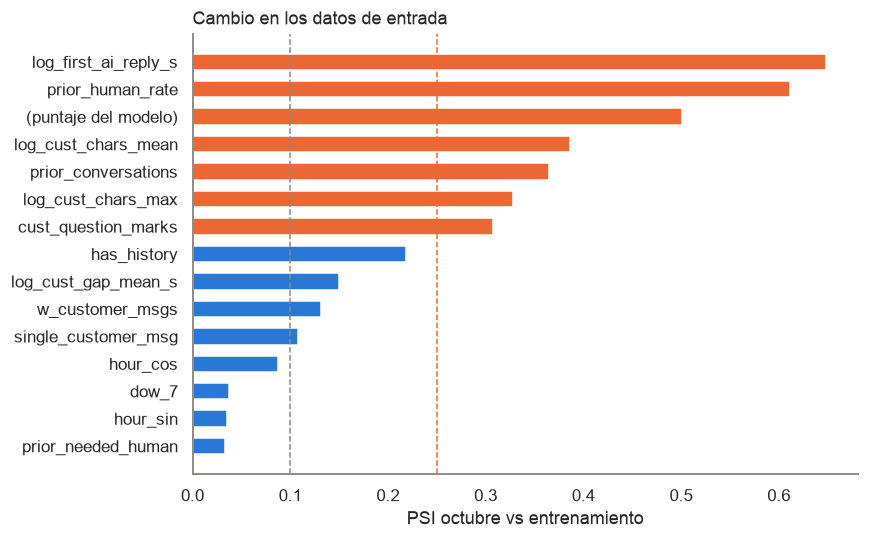

,PSI,estado
log_first_ai_reply_s,0.649,cambio fuerte
prior_human_rate,0.611,cambio fuerte
(puntaje del modelo),0.501,cambio fuerte
log_cust_chars_mean,0.387,cambio fuerte
prior_conversations,0.365,cambio fuerte
log_cust_chars_max,0.328,cambio fuerte
cust_question_marks,0.307,cambio fuerte
has_history,0.218,vigilar
log_cust_gap_mean_s,0.150,vigilar
w_customer_msgs,0.131,vigilar


In [3]:
vigente = modelos["2026-10"]
ref, octubre = rest[rest.fecha < "2026-10-01"], rest[rest.mes == "2026-10"]
drift = feature_drift(vigente, ref, octubre)
top = drift.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.PSI, color=[C1 if v >= PSI_HIGH else C0 for v in top.PSI], height=0.6)
for v, c in [(PSI_MODERATE, MUTED), (PSI_HIGH, C1)]: ax.axvline(v, color=c, ls="--", lw=1)
ax.set_xlabel("PSI octubre vs entrenamiento"); ax.set_title("Cambio en los datos de entrada", loc="left")
fig.tight_layout(); save(fig, "20_psi_octubre"); plt.show()
drift.round(3).head(15)

El PSI marca las variables cuya distribución cambió en octubre. Varias de ellas son las que
distinguen la operación de cada empresa (tiempo de respuesta, largo de los mensajes), y con E01
pasando a ser el 40 % del mes, se mueven. Las de historial (`prior_*`) cambian además de forma
natural, porque cada mes hay más clientes que vuelven. Es la
misma conclusión del EDA y del notebook 02 (cambio de mezcla), detectada aquí **sin etiquetas**: en
producción esta alarma llega días antes que la caída del recall.

### 2.2 ¿Cómo le fue al modelo? Recall, precisión y calibración por empresa

In [4]:
perf = performance_by_company(vigente, octubre)
perf.round(2)

,n,% positivos,ROC-AUC,PR-AUC,recall,precisión,% alertado,riesgo medio
TOTAL,2465.0,0.44,0.79,0.77,0.58,0.72,0.36,0.47
E01,1010.0,0.22,0.67,0.44,0.27,0.58,0.10,0.28
E02,30.0,1.00,NaN,NaN,1.00,1.00,1.00,0.94
E04,109.0,0.61,0.62,0.70,0.50,0.72,0.42,0.54
E06,427.0,0.34,0.59,0.48,0.37,0.49,0.26,0.44
E07,169.0,0.99,0.74,1.00,0.99,0.99,0.99,0.91
E08,60.0,0.95,0.91,0.99,0.95,0.98,0.92,0.87
E10,179.0,0.84,0.73,0.91,0.52,0.95,0.46,0.56
E11,17.0,0.06,0.12,0.07,0.00,0.00,0.59,0.59
E12,464.0,0.56,0.58,0.64,0.64,0.59,0.60,0.59


En la columna *riesgo medio* contra *% positivos* se lee la calibración de cada empresa. Las
empresas con pocas conversaciones en el mes tienen métricas muy ruidosas; en producción se
reportan solo con un mínimo de casos (por ejemplo, 30) o acumulando varios meses.

### 2.3 Decisión

In [5]:
ref_recall = float(((oofs["2026-10"] >= vigente.thresholds["alerta"]) & (ref[TARGET].values == 1)).sum() / ref[TARGET].sum())
decision = retrain_decision(vigente, ref_recall, perf, drift, months_since_training=1)
print("Recall de referencia (validación fuera de pliegue):", round(ref_recall, 3))
print("¿Reentrenar?", "SÍ" if decision["reentrenar"] else "no")
for r in decision["motivos"]: print("  -", r)

Recall de referencia (validación fuera de pliegue): 0.8
¿Reentrenar? SÍ
  - el recall bajó 22 puntos (0.80 → 0.58)
  - cambio fuerte (PSI ≥ 0.25) en: log_first_ai_reply_s, prior_human_rate, (puntaje del modelo), log_cust_chars_mean, prior_conversations, log_cust_chars_max, cust_question_marks


## 3. Seguimiento mes a mes

La misma revisión aplicada a agosto, septiembre y octubre, cada mes con el modelo entrenado al
inicio de ese mes. Muestra cómo evoluciona el modelo a medida que llegan datos y empresas.

,n,% positivos,ROC-AUC,PR-AUC,recall,precisión,% alertado,riesgo medio,PSI del puntaje,empresas nuevas
2026-08,215.0,0.419,0.811,0.799,0.856,0.558,0.642,0.674,0.239,2.0
2026-09,1861.0,0.643,0.544,0.688,0.602,0.655,0.591,0.588,0.718,3.0
2026-10,2465.0,0.445,0.786,0.770,0.583,0.723,0.359,0.465,0.501,0.0


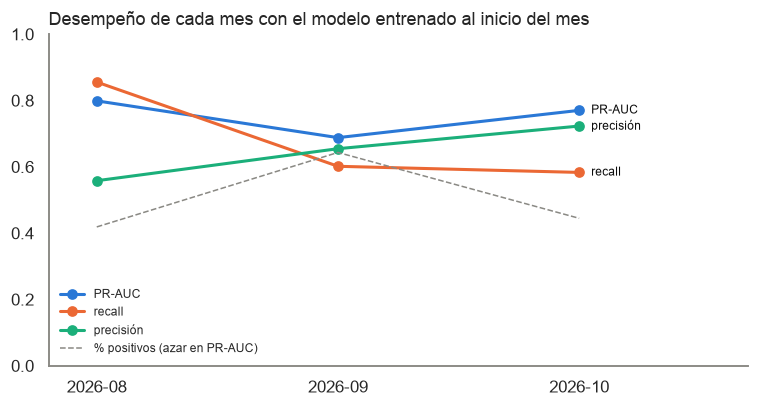

In [6]:
filas = []
for m in MESES:
    mod, mes = modelos[m], rest[rest.mes == m]
    p = performance(mes[TARGET], mod.score(mes), mod.thresholds["alerta"])
    previo = rest[rest.fecha < pd.Period(m).start_time]
    p["PSI del puntaje"] = feature_drift(mod, previo, mes).loc["(puntaje del modelo)", "PSI"]
    p["empresas nuevas"] = len(set(mes.empresa) - set(previo.empresa))
    filas.append(pd.Series(p, name=m))
mensual = pd.DataFrame(filas)
display(mensual.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
for col, c in [("PR-AUC", C0), ("recall", C1), ("precisión", C2)]:
    ax.plot(mensual.index, mensual[col], marker="o", lw=2, color=c, label=col)
    ax.text(len(mensual) - 0.95, mensual[col].iloc[-1], col, color=INK, fontsize=8, va="center")
ax.plot(mensual.index, mensual["% positivos"], color=MUTED, ls="--", lw=1, label="% positivos (azar en PR-AUC)")
ax.set_ylim(0, 1); ax.set_xlim(-0.2, len(mensual) - 0.3); ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("Desempeño de cada mes con el modelo entrenado al inicio del mes", loc="left")
fig.tight_layout(); save(fig, "21_seguimiento_mensual"); plt.show()

- **Septiembre es el peor mes (ROC-AUC ≈ 0,54):** llegan 3 empresas que el modelo de agosto nunca
  vio y que suman la mayoría de las conversaciones del mes. El PSI del puntaje lo había anunciado
  (≈ 0,7, cambio fuerte). Es la razón de la regla "reentrenar cuando entran empresas nuevas".
- **Agosto** sale bien en orden (ROC-AUC ≈ 0,81), pero con solo 215 conversaciones.
- **Octubre**, con septiembre ya en el entrenamiento, se recupera a ROC-AUC ≈ 0,79.
- Cada mes cambia la mezcla de empresas y, con ella, el recall que se obtiene con un umbral fijo.
  Además, el umbral elegido varía unas centésimas según cómo se armen los pliegues (0,54 en el
  notebook 02 y 0,57 aquí, con la misma meta de recall). Por eso el umbral se revisa en cada
  reentrenamiento y se reporta junto con su volumen de alertas.

## 4. Retador contra vigente

El vigente es el modelo del 1 de septiembre. El retador se entrena el 1 de octubre con septiembre
incluido. Se comparan **en el mismo mes (octubre), con las mismas conversaciones**, ninguna vista
por los dos modelos. Regla (`src/retrain.py`): el retador reemplaza al vigente si gana en PR-AUC y
no pierde más de 2 puntos de recall **alertando el mismo volumen de conversaciones que el vigente**.

¿Por qué a igual volumen? El recall de cada modelo con su propio umbral mezcla dos cosas: qué tan
bien ordena y dónde quedó el corte. Un retador que ordena mejor pero eligió un umbral más alto
parecería peor. A igual volumen, la comparación es justa: con la misma carga de trabajo para el
equipo, ¿cuál detecta más casos? El umbral del ganador se revisa aparte.

In [7]:
resumen, por_empresa = compare(modelos["2026-09"], modelos["2026-10"], octubre)
display(resumen.round(3))
display(por_empresa.round(3))
c, v = resumen.loc["retador"], resumen.loc["vigente"]
print("Promover retador:", "SÍ" if should_promote(resumen) else "no",
      f"(PR-AUC {v['PR-AUC']:.3f} → {c['PR-AUC']:.3f}; recall a igual volumen "
      f"{v['recall a igual volumen']:.3f} → {c['recall a igual volumen']:.3f})")

,n,% positivos,ROC-AUC,PR-AUC,recall,precisión,% alertado,riesgo medio,recall a igual volumen
vigente,2465.0,0.445,0.717,0.657,0.647,0.618,0.465,0.538,0.647
retador,2465.0,0.445,0.786,0.770,0.583,0.723,0.359,0.465,0.705


,vigente,retador
E01,0.639,0.672
E02,NaN,NaN
E04,0.700,0.623
E06,0.590,0.593
E07,0.533,0.743
E08,0.942,0.912
E10,0.710,0.733
E11,0.312,0.125
E12,0.530,0.578


Promover retador: SÍ (PR-AUC 0.657 → 0.770; recall a igual volumen 0.647 → 0.705)


## 5. Ciclo en producción

| Paso | Cuándo | Qué |
|---|---|---|
| Puntuar | En cada conversación, al llegar al 4.º mensaje sin intervención humana | `RiskModel.risk()` → riesgo, semáforo y razones. Se guarda el puntaje y la versión del modelo. |
| Etiquetar | Al cerrar la conversación | `needed_human` se calcula solo, con la misma definición del conjunto de datos. |
| Vigilar datos | Diario | PSI de variables y del puntaje (no necesita etiquetas). |
| Vigilar desempeño | Mensual | `performance_by_company`: recall, precisión, PR-AUC y calibración por empresa. Además, el **tiempo entre la alerta y el primer mensaje humano**, la medida de anticipación que el conjunto anonimizado no permite calcular. |
| Decidir | Mensual | `retrain_decision`: recall −5 puntos, empresas nuevas, PSI ≥ 0,25, descalibración > 5 puntos o 3 meses. |
| Reentrenar | Si la regla lo pide | `python src/retrain.py --holdout <mes>`: retador contra vigente en el último mes. |
| Desplegar | Si el retador gana | Corre **en paralelo** una o dos semanas, guardando ambos puntajes sin mostrar el nuevo; luego reemplaza al vigente. El artefacto anterior se conserva para **volver atrás** con un cambio de configuración. |

**Cuidados:**
- No reentrenar con conversaciones aún abiertas: su etiqueta no es definitiva.
- El historial del cliente (`prior_*`) solo debe contar conversaciones **cerradas** antes de la actual.
- Si cambia el modelo de IA de la plataforma, se reentrena aunque las métricas no hayan caído, porque
  cambia la forma de las respuestas automáticas.

## 6. Conclusiones
1. **El monitoreo detecta el problema sin etiquetas.** En octubre el PSI del puntaje fue 0,50
   (cambio fuerte) y en septiembre 0,72, antes de conocer cuántas conversaciones necesitaron
   persona.
2. **Con etiquetas, la regla pide reentrenar en octubre:** el recall cae de 0,80 (validación) a
   ≈ 0,58, y siete variables tienen PSI ≥ 0,25.
3. **Reentrenar sirve:** el retador del 1 de octubre, que incluye septiembre, le gana al modelo del 1
   de septiembre en el mismo octubre: PR-AUC 0,66 → 0,77 y más recall con la misma carga de alertas.
4. **La regla de promoción compara a igual volumen de alertas**, para no castigar a un retador que
   ordena mejor solo porque su umbral cayó en otro punto. Esto salió de este mismo análisis: con la
   comparación ingenua de recall, el retador se habría rechazado.
5. **Las empresas nuevas son el mayor riesgo** (septiembre, ROC-AUC 0,54). Con un negocio nuevo, el
   modelo se usa para ordenar la cola, no para alertar, hasta tener un mes de datos suyos.